# Application 12 · A convex hull that is not convex enough

**Builds on:** [Lecture 12](../notebooks/12_robust_geometry.ipynb) (filtered orientation predicate) and Lecture 02 (binary64 numbers are exact rationals).

**Time:** about 50 minutes. **You will see:** a textbook convex-hull algorithm, run on nine ordinary binary64 points, return a polygon that leaves one of the input points **outside**. Then you will fix it by changing one function.

The examples follow Kettner, Mehlhorn, Pion, Schirra and Yap, *Classroom examples of robustness problems in geometric computations* (2008), a paper written for exactly this kind of course.

## Google Colab setup — run this cell first

**Local Jupyter:** this cell skips Colab setup; use your installed course environment.

Use a **CPU Python runtime** (Python 3.12 or newer). Run the next cell and select
**vc_runtime.zip** from this edition when prompted. It loads the course helpers
and installs the arithmetic libraries. Repeat setup whenever you get a new runtime.
No Drive mounting or local Python installation is required.
Use this setup instead of the local installation and kernel-selection instructions
in the original course text.

Save a copy of this notebook in Drive, or download it after editing. Files created
by the project are under `/content/validated-course/build/certificates/`; download
those separately from Colab's Files panel. Runtime files are temporary.

Open other course notebooks using **File → Upload notebook**, choosing them from
the extracted course folder. Relative course links are intended for local Jupyter
and do not open sibling notebooks automatically in Colab.


In [1]:
try:
    import google.colab
except ImportError:
    print("Local Jupyter: using the installed course environment.")
else:
    import hashlib
    from pathlib import Path
    import subprocess
    import sys
    from google.colab import files

    if sys.version_info < (3, 12):
        raise RuntimeError("This course needs a Python 3.12 or newer Colab runtime.")

    # Upload the small companion file supplied with the Colab course edition.
    expected_hash = '833652c4a440f1c3a22bc6e68c59d533b41e6f9f1ff0b4af226f8fbee2244c1a'
    runtime_zip = Path("/content") / ("vc-course-" + expected_hash + ".zip")
    if not runtime_zip.exists():
        print("Select vc_runtime.zip from the extracted Colab course folder.")
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise ValueError("Upload only vc_runtime.zip, then run this cell again.")
        archive_bytes = next(iter(uploaded.values()))
        if hashlib.sha256(archive_bytes).hexdigest() != expected_hash:
            raise ValueError("Wrong vc_runtime.zip: use the one supplied with this notebook.")
        runtime_zip.write_bytes(archive_bytes)

    if hashlib.sha256(runtime_zip.read_bytes()).hexdigest() != expected_hash:
        raise ValueError("The cached vc archive has changed; start a fresh runtime.")

    # Keep Colab's existing NumPy and plotting stack when they satisfy these bounds.
    # Install MPFR/Arb bindings, not the full local Jupyter environment.
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet",
        'numpy>=1.26', 'matplotlib>=3.8', 'gmpy2==2.3.1', 'python-flint==0.9.0', 'jupytext>=1.16'
    ])
    import gmpy2
    import flint
    if gmpy2.version() != "2.3.1" or flint.__version__ != "0.9.0":
        raise RuntimeError("Old arithmetic libraries are still loaded. Restart the session and run setup first.")

    if str(runtime_zip) not in sys.path:
        sys.path.insert(0, str(runtime_zip))

    import vc
    if not vc.__file__.startswith(str(runtime_zip) + "/"):
        raise RuntimeError("Another vc copy is already loaded. Start a fresh runtime.")

    # Preserve the relative output paths used by the project notebooks.
    import os
    working_folder = Path("/content/validated-course") / 'applications'
    working_folder.mkdir(parents=True, exist_ok=True)
    os.chdir(working_folder)
    print("Course helpers ready:", vc.__version__)

Local Jupyter: using the installed course environment.


In [2]:
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from vc.geometry import orientation, determinant

## 1 · Two orientation tests

For points a, b, c the sign of

$$\det(a,b,c)=(b_x-a_x)(c_y-a_y)-(b_y-a_y)(c_x-a_x)$$

says whether c is left of (+1), on (0), or right of (−1) the directed line a→b. The float version rounds every operation. The exact version treats each binary64 input as the exact rational it is (`Fraction` of a float is exact) and uses `vc.geometry.orientation`, which tries cheap Arb filters first and falls back to exact rational arithmetic only when needed.

In [3]:
def float_orientation(a, b, c):
    det = (b[0] - a[0]) * (c[1] - a[1]) - (b[1] - a[1]) * (c[0] - a[0])
    return (det > 0) - (det < 0)

def exact_point(p):
    return (Fraction.from_float(p[0]), Fraction.from_float(p[1]))

def exact_orientation(a, b, c):
    return orientation(exact_point(a), exact_point(b), exact_point(c)).sign

## 2 · The orientation map

Take q = (12, 12) and r = (24, 24), and points p on a 256 × 256 grid of neighbouring binary64 numbers near (1/2, 1/2): p = (1/2 + i·u, 1/2 + j·u) with u = 2⁻⁵³. Color p by the sign of orient(p, q, r). Exactly, the line y = x splits the grid cleanly. In floating point the map is noisy.

In [4]:
u = 2.0**-53
steps = range(256)                 # plain Python ints keep every coordinate a Python float
float_map = np.zeros((256, 256))
exact_map = np.zeros((256, 256))
q, r = (12.0, 12.0), (24.0, 24.0)
for i in steps:
    for j in steps:
        p = (0.5 + i * u, 0.5 + j * u)
        float_map[j, i] = float_orientation(p, q, r)
        exact_map[j, i] = np.sign(determinant(exact_point(p), exact_point(q), exact_point(r)))

wrong = np.sum(float_map != exact_map)
print(f"float sign differs from the exact sign for {wrong} of {256*256} points")

float sign differs from the exact sign for 11972 of 65536 points


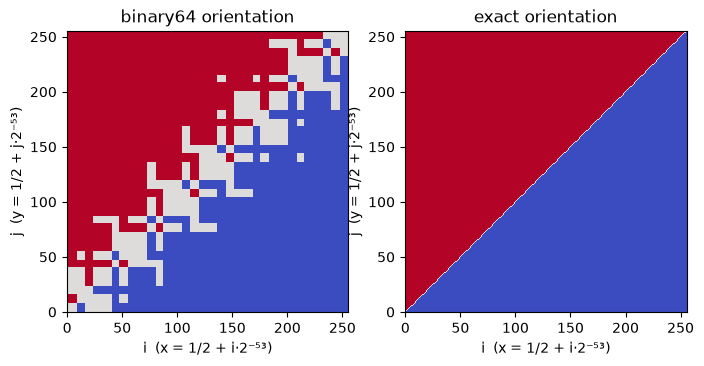

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, sign_map, title in [(axes[0], float_map, "binary64 orientation"),
                            (axes[1], exact_map, "exact orientation")]:
    ax.imshow(sign_map, origin="lower", cmap="coolwarm", vmin=-1, vmax=1, interpolation="nearest")
    ax.set(title=title, xlabel="i  (x = 1/2 + i·2⁻⁵³)", ylabel="j  (y = 1/2 + j·2⁻⁵³)")
plt.close(fig)
display(fig)

Red: left turn, blue: right turn, white: collinear. The float map is wrong in a large wedge around the true line, and its errors are not even consistent (a point can be classified "left" while its neighbours on both sides are classified "right"). An algorithm that relies on consistent answers can then do anything.

## 3 · Andrew's monotone chain algorithm

Sort the points, then build the lower and upper hull, popping the last point while it does not make a strict left turn. The orientation test is a parameter.

In [6]:
def convex_hull(points, orient):
    ordered = sorted(set(points))
    def half_hull(sequence):
        chain = []
        for p in sequence:
            while len(chain) >= 2 and orient(chain[-2], chain[-1], p) <= 0:
                chain.pop()
            chain.append(p)
        return chain
    lower = half_hull(ordered)
    upper = half_hull(reversed(ordered))
    return lower[:-1] + upper[:-1]          # counterclockwise, no repeated end points

**A checker that we trust.** A counterclockwise polygon is the convex hull of the points only if every vertex is a strict left turn and every input point is on or left of every edge. We check this with exact arithmetic. The checker does not depend on how the hull was computed.

In [7]:
def hull_problems(hull, points):
    problems = []
    n = len(hull)
    for k in range(n):
        a, b, c = hull[k], hull[(k + 1) % n], hull[(k + 2) % n]
        if exact_orientation(a, b, c) <= 0:
            problems.append(f"vertex {b} is not a strict left turn")
        for p in points:
            if exact_orientation(a, b, p) < 0:
                problems.append(f"point {p} lies outside edge {a} -> {b}")
    return problems

## 4 · Nine points

Seven points lie very close to the line y = x (as measured positions on a straight edge would), plus two clearly separate points. All coordinates are ordinary binary64 numbers.

In [8]:
points = [
    (0.5, 0.5),
    (12.0, 12.0),
    (24.0, 24.0),
    (19.4156853472275, 19.415685347227548),
    (18.461553344437615, 18.46155334443769),
    (29.91629807367633, 29.916298073676295),
    (29.4250601632869, 29.425060163286865),
    (19.513778288034487, 19.513778288034537),
    (0.0, 30.0),
]

float_hull = convex_hull(points, float_orientation)
exact_hull = convex_hull(points, exact_orientation)
print("float hull:", float_hull)
print("problems:  ", hull_problems(float_hull, points))
print()
print("exact hull:", exact_hull)
print("problems:  ", hull_problems(exact_hull, points))

float hull: [(0.0, 30.0), (0.5, 0.5), (29.91629807367633, 29.916298073676295)]
problems:   ['point (29.4250601632869, 29.425060163286865) lies outside edge (0.5, 0.5) -> (29.91629807367633, 29.916298073676295)']

exact hull: [(0.0, 30.0), (0.5, 0.5), (29.4250601632869, 29.425060163286865), (29.91629807367633, 29.916298073676295)]
problems:   []


The float hull is a triangle, and the point (29.425…, 29.425…) lies strictly outside it. The exact hull has four vertices. The difference is about 10⁻¹⁴, invisible in a plot of the points, but it breaks the defining property of a convex hull. Any later step that relies on it (a containment query, a collision test, a mesh generator) inherits a wrong answer.

To see the difference, we plot each point's **exact** signed distance from the long edge of the float hull. Points with positive distance are outside the float hull.

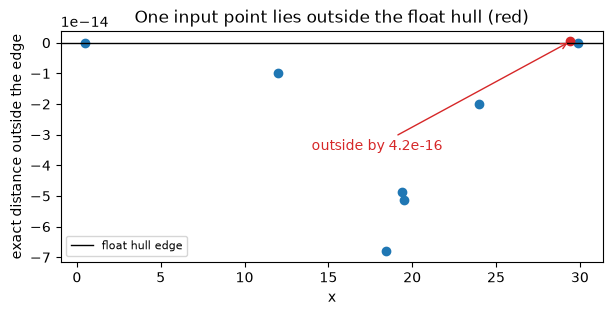

In [9]:
a, b = exact_point(float_hull[1]), exact_point(float_hull[2])      # the long edge (0.5,0.5) -> (29.9...)
edge_length = float(((b[0] - a[0])**2 + (b[1] - a[1])**2) ** 0.5)
fig, ax = plt.subplots(figsize=(7, 3))
for p in points[:-1]:                                              # skip the far point (0, 30)
    distance = -float(determinant(a, b, exact_point(p))) / edge_length
    outside = distance > 0
    ax.plot(p[0], distance, "o", color="tab:red" if outside else "tab:blue")
    if outside:
        ax.annotate(f"outside by {distance:.1e}", (p[0], distance), xytext=(14, -3.5e-14),
                    arrowprops={"arrowstyle": "->", "color": "tab:red"}, color="tab:red")
ax.axhline(0, color="black", linewidth=1, label="float hull edge")
ax.set(xlabel="x", ylabel="exact distance outside the edge",
       title="One input point lies outside the float hull (red)")
ax.legend(loc="lower left", fontsize=8)
plt.close(fig)
display(fig)

## 5 · Cost of exactness

The filtered predicate answers most queries in Arb at low precision and needs exact rationals only for nearly degenerate triples. Count how often each method decided.

In [10]:
from collections import Counter
methods = Counter()
def counting_orientation(a, b, c):
    result = orientation(exact_point(a), exact_point(b), exact_point(c))
    methods[result.method] += 1
    return result.sign

convex_hull(points, counting_orientation)
print("decided by:", dict(methods))

decided by: {'arb': 22}


**What is guaranteed.** With exact orientation, the algorithm's standard correctness proof applies word for word, because the proof only uses the sign of the determinant. The guarantee concerns the binary64 inputs as given. If the points are *measurements* with uncertainty, the correct question changes (Lab 12, Task C): some orientations are then genuinely undecidable, and the honest output is a set of possible hulls.

## Exercises

1. **Point in polygon.** Write `inside(polygon, p, orient)` for a convex counterclockwise polygon: p is inside if it is left of or on every edge. Find a binary64 point that the float version classifies differently from the exact version, using the polygon from Section 4.
2. **Random search.** Generate 2000 random sets of points within a few ulps of the line y = x (use `np.nextafter`). In what fraction does the float hull fail the checker? Does the failure rate depend on where along the line the points are?
3. **A different line.** Repeat Section 2 with q = (12, 12) and r = (24, 24.000000000000004). How does the float map change?
4. **Measurements.** Treat each coordinate as an interval of radius 10⁻¹² and use `vc.geometry.orientation_bound`. Which orientation decisions in the hull computation become undecidable? What should a robust program output then?